# La banda de dependencia y las cotas del VaR del peor caso

**Pregunta:** ¿Es la suma simple lo máximo que podrían necesitar en capital los cuatro riesgos de Banco Andino, y entre qué dos
números debe quedar toda respuesta diversificada sea cual sea la dependencia entre los riesgos?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema (la suma simple, las cópulas y la banda versionada)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar por qué el VaR comonótono, el VaR de riesgos perfectamente dependientes, no es el peor caso, con un ejemplo
  publicado cuya respuesta se conoce;
- seguir el algoritmo de reordenamiento en una matriz lo bastante pequeña para imprimirla y decir qué hace con las sumas por
  fila;
- ejecutar la banda del motor sobre las cuatro marginales de Banco Andino y leer cada fila, titular o informativa, con su
  dependencia de la matriz de correlación;
- comprobar que cada fila queda dentro de la cota que definen el mejor y el peor VaR, y ver la comprobación ponerse roja cuando
  se empuja una fila hacia afuera;
- leer qué mueve un estrés de correlación en la banda y qué no puede mover.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.aggregation import band as rv_band
from riskvalidation.aggregation import bounds
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este notebook lee el mismo caso de los notebooks 01 y 02, **C18** (Banco Andino).

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginales, matriz, banda versionada), `data/derived/C18/t-copula-baseline.json` (`outputs.correlation_stress`: la misma banda con la correlación mercado-crédito subida a 0,8) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`, las funciones de cuantiles de las marginales).
- **Las marginales se reconstruyen desde las grillas de cuantiles versionadas en los pasos simulados.** Igual que en el notebook 02, el documento de modelos tiene la función de cuantiles de cada marginal sobre una grilla nombrada y no las pérdidas simuladas, así que el paso 3 reconstruye las cuatro marginales desde ella y corre la banda sobre ellas con los ajustes del flujo de generación; se espera recuperar la banda versionada con error menor que 0,01 por ciento. Los pasos 1 y 2 usan en cambio un ejemplo publicado con marginales en forma cerrada, para poder comprobar el algoritmo contra una fórmula.

In [2]:
# Los bloques de agregación base y estresado y las grillas de cuantiles versionadas de las cuatro marginales
agg = read_json("C18/baseline.json")["outputs"]["aggregation"]
stress = read_json("C18/t-copula-baseline.json")["outputs"]["correlation_stress"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
marginals = agg["marginals"]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
stressed = {(r["method"], r["nu"]): r for r in stress["aggregation"]["band"]}
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple",
         "variance-covariance": "varianza-covarianza", "gaussian-copula": "cópula gaussiana",
         "t-copula": "cópula t", "worst-case": "peor caso"}

## Método

### Paso 1: el VaR comonotónico no es el peor caso

Cuando la dependencia entre los riesgos es desconocida, una cota superior natural pero errada es el **VaR comonotónico**, el VaR de la suma cuando los riesgos se mueven juntos de forma perfecta: $\mathrm{VaR}_q(L_1 + \dots + L_d) = \sum_k F_k^{-1}(q)$. Es la suma simple de los VaR, exacta para dependencia perfecta. Pero **el VaR no es subaditivo**, así que alguna otra dependencia puede dar un VaR de la suma mayor (Embrechts, McNeil y Straumann 2002; Embrechts, Puccetti y Rueschendorf 2013). El motor calcula el mejor y el peor VaR exactos sobre todas las estructuras de dependencia, dadas solo las marginales.

El ejemplo publicado de Embrechts, Puccetti y Rueschendorf (2013, Tabla 4) usa marginales Pareto(2), $F(x) = 1 - (1+x)^{-2}$, de modo que $F^{-1}(q) = (1-q)^{-1/2} - 1$ en forma cerrada, con $d = 8$ riesgos.

La celda siguiente construye las ocho funciones de cuantiles Pareto(2) como la distribución Lomax de scipy, ejecuta
`comonotonic_var` y `worst_var_bounds` con los ajustes del flujo ($N = 10^5$ celdas, $\epsilon = 10^{-3}$), e imprime los
tres VaR.

In [3]:
# Ocho marginales Pareto(2) del ejemplo publicado: el VaR comonótono y luego las cotas agudas
D, Q = 8, 0.99
pareto = [partial(stats.lomax.ppf, c=2)] * D
como = bounds.comonotonic_var(pareto, Q)
sharp = bounds.worst_var_bounds(pareto, Q, 100_000, 1e-3, seed=0)
print("VaR comonótono", round(como, 4), "forma cerrada", round(D * ((1 - Q) ** -0.5 - 1), 4))
print("rango del mejor VaR", np.round(sharp.lower_range, 3))
print("rango del peor VaR", np.round(sharp.upper_range, 3))
print("barridos de las cuatro corridas", sharp.sweeps, "convergió", sharp.converged)
print("peor VaR sobre el VaR comonótono", round(sharp.upper_range[1] / como, 3))

VaR comonótono 72.0 forma cerrada 72.0
rango del mejor VaR [8.995 9.   ]
rango del peor VaR [141.663 141.669]
barridos de las cuatro corridas (4, 4, 5, 5) convergió True
peor VaR sobre el VaR comonótono 1.968


El VaR comonótono es 72,0, que es lo que da la forma cerrada para ocho riesgos Pareto(2) al 99 por ciento, y el peor VaR es
141,66 a 141,67, 1,968 veces mayor. El mejor VaR, 9,00, queda muy por debajo. La celda siguiente repite la corrida con dos a
ocho riesgos para mostrar cómo crecen los tres números con la cantidad de riesgos.

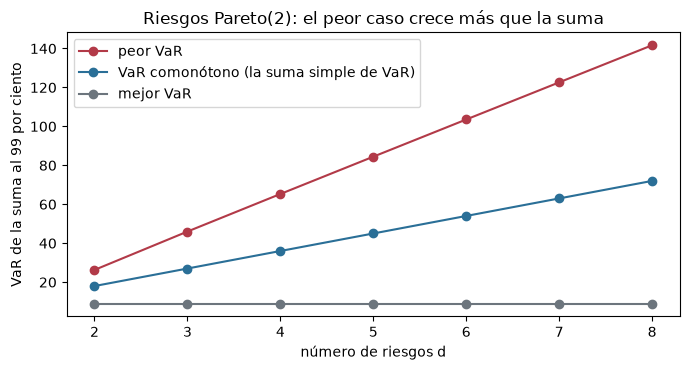

In [4]:
# El VaR comonótono, el mejor y el peor de d riesgos Pareto(2) cuando d crece de 2 a 8
sizes = list(range(2, 9))
runs = [bounds.worst_var_bounds([pareto[0]] * d, Q, 100_000, 1e-3, seed=0) for d in sizes]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(sizes, [r.upper_range[1] for r in runs], marker="o", color="#b23a48", label="peor VaR")
ax.plot(sizes, [bounds.comonotonic_var([pareto[0]] * d, Q) for d in sizes], marker="o", color="#2a6f97",
        label="VaR comonótono (la suma simple de VaR)")
ax.plot(sizes, [r.lower_range[0] for r in runs], marker="o", color="#6c757d", label="mejor VaR")
ax.set_xlabel("número de riesgos d")
ax.set_ylabel("VaR de la suma al 99 por ciento")
ax.set_title("Riesgos Pareto(2): el peor caso crece más que la suma")
ax.legend()
fig.tight_layout()
plt.show()

Con dos riesgos el peor VaR ya es 26,3 frente a un comonótono de 18,0, y la brecha se ensancha con cada riesgo añadido: con
ocho el peor caso es cerca del doble de la suma de los VaR. El mejor VaR se queda cerca de 9 sea cual sea el número de
riesgos, porque el mejor arreglo deja que los riesgos se cancelen casi por completo en la cola. Las tres líneas son todo el
ancho de lo que la dependencia puede hacer con el VaR de una suma de riesgos de cola pesada, y la suma simple es la del medio,
no la de arriba. La figura es un ejemplo publicado en forma cerrada y no Banco Andino, que llega en el paso 3.

### Paso 2: cómo funciona el algoritmo de reordenamiento

El peor VaR es el mayor valor que puede tomar la **menor** suma de fila. Se toma el $1 - q$ superior de cada marginal, se corta en $N$ celdas y se ponen los cuantiles de las celdas en una matriz $X$ de $N$ filas y $d$ columnas. Toda dependencia en la cola es una permutación de cada columna. El **algoritmo de reordenamiento** (Embrechts, Puccetti y Rueschendorf 2013, sección 2.2) busca la permutación que hace las sumas de fila lo más iguales posible: permuta las columnas al azar y luego, una columna a la vez, la reordena **de forma opuesta** a la suma de las otras (el valor mayor junto al menor resto), y repite hasta que la menor suma de fila cambia en menos de $\epsilon$. Igualar todas las sumas de fila es la "mezclabilidad conjunta" que da el peor caso: ninguna fila queda con un total pequeño.

La celda siguiente toma tres riesgos Pareto(2) y diez celdas sobre el uno por ciento superior, y llama a
`rearrangement_algorithm`. La figura muestra las sumas por fila de la matriz comonótona junto a las de la reordenada.

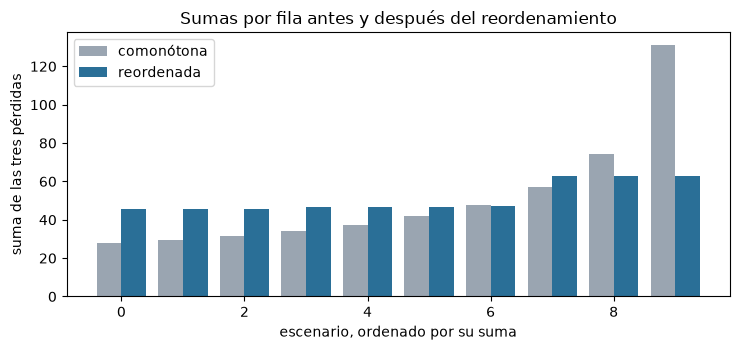

menor suma por fila, comonótona y reordenada 27.78 45.39
barridos 4 convergió True


In [5]:
# Una matriz de 10 x 3 de cuantiles de celda: las sumas por fila comonótonas y las reordenadas
cells = 10
midpoints = Q + (1 - Q) * (np.arange(cells) + 0.5) / cells
matrix = np.column_stack([pareto[0](midpoints)] * 3)
rearranged, value, sweeps, converged = bounds.rearrangement_algorithm(matrix, "max-min-row-sum", 1e-3, 1000, 0)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
scenario = np.arange(cells)
ax.bar(scenario - 0.2, np.sort(matrix.sum(axis=1)), width=0.4, color="#9aa5b1", label="comonótona")
ax.bar(scenario + 0.2, np.sort(rearranged.sum(axis=1)), width=0.4, color="#2a6f97", label="reordenada")
ax.set_xlabel("escenario, ordenado por su suma")
ax.set_ylabel("suma de las tres pérdidas")
ax.set_title("Sumas por fila antes y después del reordenamiento")
ax.legend()
fig.tight_layout()
plt.show()
print("menor suma por fila, comonótona y reordenada", round(matrix.sum(axis=1).min(), 2), round(value, 2))
print("barridos", sweeps, "convergió", converged)

El reordenamiento solo mueve valores dentro de cada columna, así que las tres marginales quedan intactas, y aun así la menor
suma por fila sube de 27,78 a 45,39 y las sumas se agrupan en un rango estrecho de 45 a 63, contra 28 a 131 antes. Ese es el
mecanismo por el que una estructura de dependencia puede pedir mucho más capital que la dependencia perfecta: reparte las
pérdidas extremas entre escenarios de modo que todo escenario es malo, mientras que el arreglo comonótono las amontona en un
escenario y deja el resto benigno. El algoritmo convergió en cuatro barridos; un VaR de la suma es la menor de estas sumas en el
peor arreglo.

### Paso 3: las marginales de Banco Andino

Para las cuatro marginales del caso, el documento de modelos tiene las funciones de cuantiles en la grilla nombrada del
notebook 02 (1.961 probabilidades, lineales en la probabilidad entre puntos y acotadas en los extremos). La celda siguiente
las reconstruye, lee de cada una una muestra de $10^6$ posiciones de Hazen, dibuja el cuantil de pérdida de cada una contra el
nivel de probabilidad e imprime el VaR comonótono de las cuatro, que menos la suma de las pérdidas esperadas es la suma simple.

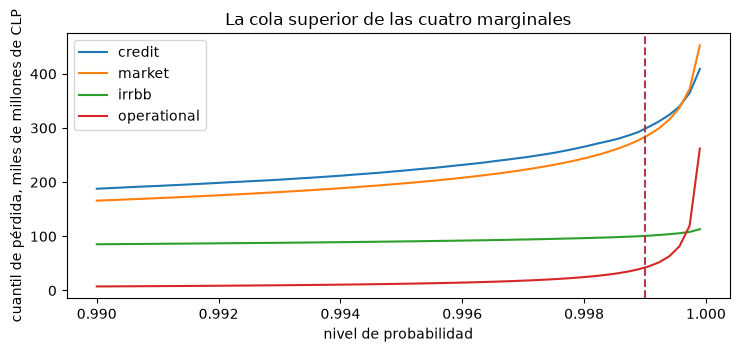

VaR comonótono de las cuatro, millones de CLP 724858.9
suma de las pérdidas esperadas 66728.7
VaR comonótono menos las pérdidas esperadas 658130.2


In [6]:
# Reconstruir las cuatro marginales desde las grillas versionadas y leer el VaR comonótono de las cuatro
LEVEL = 0.999
probs = np.array(grid["probabilities"])
ppfs = [partial(np.interp, xp=probs, fp=np.array(q["quantiles"])) for q in grid["marginals"]]
ec = np.array([m["ec_clp_m"] for m in marginals])
el = np.array([m["el_clp_m"] for m in marginals])
levels = np.linspace(0.99, 0.9999, 60)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for m, ppf in zip(marginals, ppfs):
    ax.plot(levels, ppf(levels) / 1e3, label=m["risk"])
ax.axvline(LEVEL, color="#b23a48", linestyle="--")
ax.set_xlabel("nivel de probabilidad")
ax.set_ylabel("cuantil de pérdida, miles de millones de CLP")
ax.set_title("La cola superior de las cuatro marginales")
ax.legend()
fig.tight_layout()
plt.show()
como_four = bounds.comonotonic_var(ppfs, LEVEL)
print("VaR comonótono de las cuatro, millones de CLP", round(como_four, 1))
print("suma de las pérdidas esperadas", round(el.sum(), 1))
print("VaR comonótono menos las pérdidas esperadas", round(como_four - el.sum(), 1))

La línea discontinua es el nivel de 99,9 por ciento del caso. A su izquierda las cuatro funciones de cuantiles suben con
suavidad; a su derecha el riesgo operacional y el crédito se curvan hacia arriba, y la marginal de cola pesada importa más
cuanto más adentro de la cola mira la banda. El motor lee el VaR comonótono de las cuatro como 724.859 millones de pesos, y
quitar los 66.729 de pérdida esperada da 658.130, la suma simple del notebook 01 con el redondeo de la grilla. Las curvas son la
entrada de todo lo que sigue: la banda, como toda agregación, solo puede ser tan buena como estas cuatro colas.

### Paso 4: la banda

`dependence_band` pone todo sobre las mismas marginales, un horizonte y un nivel de confianza, y devuelve la **banda**, nunca una sola cifra diversificada:

| Fila | Cómo se calcula | ¿Depende de la matriz? |
|---|---|---|
| cota inferior | el mejor VaR de `worst_var_bounds` (su `lower_range[0]`) menos la suma de las pérdidas esperadas; con signo | no |
| suma simple | $\sum_k EC_k$, el capital **principal** | no |
| varianza-covarianza | $\sqrt{EC^{\top} R\, EC}$ | sí |
| cópula gaussiana | `copula_aggregate` | sí |
| cópula t, una fila por $\nu$ | `copula_aggregate` | sí |
| peor caso | el peor VaR de `worst_var_bounds` (su `upper_range[1]`) menos la suma de las pérdidas esperadas | no |

Cada fila es capital económico en la base $EC = \mathrm{VaR} - \mathrm{EL}$; la suma simple tiene el estado `headline-capital` y toda otra fila `information-not-capital`, de modo que una cifra diversificada no se confunde con el capital. Una fila sobre el capital principal es un resultado verdadero y lo informa la prueba de signo, nunca se repara.

La celda siguiente ejecuta la banda con los ajustes del flujo (un millón de simulaciones, $10^5$ celdas de cota, semilla 42)
y dibuja sus filas como barras con la cota entre la cota inferior y el peor caso sombreada.

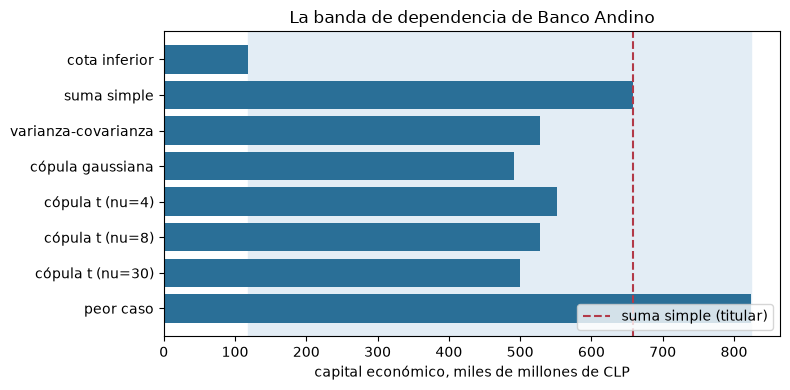

cota inferior             118,509  0.1801 information-not-capital
suma simple               658,046  1.0000 headline-capital
varianza-covarianza       528,106  0.8025 information-not-capital
cópula gaussiana          491,999  0.7477 information-not-capital
cópula t                  552,369  0.8394 information-not-capital
cópula t                  528,318  0.8029 information-not-capital
cópula t                  499,133  0.7585 information-not-capital
peor caso                 823,347  1.2512 information-not-capital


In [7]:
# Ejecutar toda la banda sobre las marginales reconstruidas con los ajustes del flujo y dibujarla con su cota
band = rv_band.dependence_band(ppfs, ec, el, R, NU_SET, level=LEVEL, horizon_years=1, n_draws=1_000_000, seed=42,
                               chunk_size=100_000, bounds_n=100_000, bounds_epsilon=1e-3,
                               ec_consistency_tolerance=0.01)
rows = {(r.method, r.nu): r for r in band.rows}
labels = [NAMES[r.method] + (f" (nu={r.nu:g})" if r.nu else "") for r in band.rows]
values = [r.capital / 1e3 for r in band.rows]
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(rows[("lower-bound", None)].capital / 1e3, rows[("worst-case", None)].capital / 1e3, color="#e3edf5")
ax.barh(labels[::-1], values[::-1], color="#2a6f97")
ax.axvline(band.headline / 1e3, color="#b23a48", linestyle="--", label="suma simple (titular)")
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_title("La banda de dependencia de Banco Andino")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
for r in band.rows:
    print(f"{NAMES[r.method]:22s} {r.capital:10,.0f} {r.diversification_factor:7.4f} {r.status}")

Cada fila de la banda queda dentro de la cota sombreada, desde la cota inferior en 118.509 millones de pesos hasta el peor caso
en 823.347 millones, y el titular discontinuo no es ni su techo ni su piso. La suma simple (658.046) y la fila de la raíz
cuadrada (528.106) usan solo los capitales versionados, así que no cambian respecto de las formas cerradas del notebook 01;
las dos cotas salen de las marginales reconstruidas y caen sobre las versionadas dentro de 0,01 por ciento; las filas de
cópula son las del notebook 02. Importan los estados impresos junto a los números: solo la suma simple es `headline-capital`,
todas las demás filas son `information-not-capital`, de modo que una cifra diversificada no puede confundirse con el capital
del caso.

### Paso 5: la regla estructural de la banda

Sean cuales sean las marginales, la cota inferior es el mejor VaR posible de la suma sobre toda estructura de dependencia y el
peor caso es el peor posible, así que **toda otra fila de la banda queda entre ellos**. La prueba `worst_case_bracket` del
motor lo comprueba: roja cuando alguna fila queda fuera de la cota, verde en otro caso. La celda siguiente la ejecuta sobre la
banda de este notebook y sobre una copia en que la fila gaussiana se ha duplicado a propósito, para ver a la prueba rechazar.

In [8]:
# Ejecutar la prueba de cota sobre la banda de este notebook y sobre una con la fila gaussiana duplicada fuera
# de la cota
capital = {key: r.capital for key, r in rows.items()}
inner = [v for (method, nu), v in capital.items() if method not in ("lower-bound", "worst-case")]
lower, worst = capital[("lower-bound", None)], capital[("worst-case", None)]
pushed = [2 * v if v == capital[("gaussian-copula", None)] else v for v in inner]
for label, between in (("la banda de este notebook", inner), ("una fila empujada afuera", pushed)):
    result = agg_tests.worst_case_bracket(lower, between, worst)
    print(f"{label:28s} {"luz"} {LIGHT[result.light.value]:6s} {"filas afuera"} {result.extras['rows_outside']}")

la banda de este notebook    luz verde  filas afuera 0
una fila empujada afuera     luz rojo   filas afuera 1


### Paso 6: qué mueve el estrés de la correlación

El caso vuelve a correr la banda con la correlación mercado-crédito subida de 0,5 a 0,8, el extremo superior de los rangos publicados (dossier 05, G.5). Las tres filas que no dependen de la matriz no pueden moverse; las tres clases que sí dependen, se moverán. La prueba `correlation_stress` del motor lee el cambio de la fila gaussiana frente a un umbral ámbar.

La celda siguiente recalcula la fila de la raíz cuadrada con la matriz estresada mediante `variance_covariance`, ejecuta la
prueba `correlation_stress` del motor sobre las dos filas gaussianas y dibuja la banda versionada bajo la matriz base y la
estresada.

par estresado market credit 0.8
fila de la raíz cuadrada, matriz estresada 568520.5
cambio gaussiano y umbral ámbar 0.1211 0.1


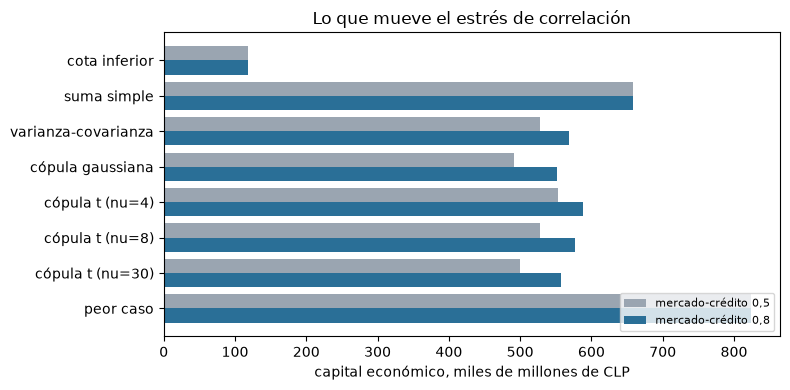

{'cota inferior None': 0.0, 'suma simple None': 0.0, 'varianza-covarianza None': 0.077, 'cópula gaussiana None': 0.121, 'cópula t 4.0': 0.064, 'cópula t 8.0': 0.092, 'cópula t 30.0': 0.116, 'peor caso None': 0.0}
fila gaussiana, porcentaje 12.1


In [9]:
# Recalcular la fila de la raíz cuadrada de la matriz estresada, ejecutar la prueba de estrés y dibujar ambas
# bandas
R_stress = np.array(stress["aggregation"]["correlation"]["matrix"])
print("par estresado", stress["pair"]["a"], stress["pair"]["b"], stress["pair"]["value"])
print("fila de la raíz cuadrada, matriz estresada", round(simple.variance_covariance(ec, R_stress), 1))
keys = list(committed)
gaussian = ("gaussian-copula", None)
test = agg_tests.correlation_stress(committed[gaussian]["capital_clp_m"], stressed[gaussian]["capital_clp_m"])
print("cambio gaussiano y umbral ámbar", round(test.statistic, 4), test.extras["thresholds"]["amber"])
y = np.arange(len(keys))[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
base_bn = [committed[k]["capital_clp_m"] / 1e3 for k in keys]
stress_bn = [stressed[k]["capital_clp_m"] / 1e3 for k in keys]
ax.barh(y + 0.2, base_bn, height=0.4, color="#9aa5b1", label="mercado-crédito 0,5")
ax.barh(y - 0.2, stress_bn, height=0.4, color="#2a6f97", label="mercado-crédito 0,8")
ax.set_yticks(y)
ax.set_yticklabels([NAMES[k[0]] + (f" (nu={k[1]:g})" if k[1] else "") for k in keys])
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_title("Lo que mueve el estrés de correlación")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
change = {k: stressed[k]["capital_clp_m"] / committed[k]["capital_clp_m"] - 1 for k in keys}
print({f"{NAMES[k[0]]} {k[1]}": round(v, 3) for k, v in change.items()})
print("fila gaussiana, porcentaje", round(change[gaussian] * 100, 1))

Las tres filas que no dependen de la matriz, la cota inferior, la suma simple y el peor caso, son idénticas en ambas bandas, y
todas las otras se mueven a la derecha. Subir la correlación mercado-crédito de 0,5 a 0,8, el extremo de los rangos
publicados, eleva la fila de la raíz cuadrada 7,7 por ciento a 568.521 y la fila gaussiana 12,1 por ciento, y la prueba del
motor lee el cambio gaussiano, 0,1211, contra su umbral de 0,1 y se pone ámbar. Las filas t suben 6,4; 9,2 y 11,6 por ciento
con cuatro, ocho y treinta grados de libertad. Incluso las filas estresadas quedan dentro de la cota y bajo el peor caso, que
es el sentido de tener una cota: no depende de la matriz que un estrés cambia.

## Resultados

**Respuesta:** no, la suma simple no es lo máximo que podrían necesitar los cuatro riesgos. Sobre toda dependencia posible el
peor VaR de la suma pide 823.347 millones de pesos, 1,25 veces la suma simple de 658.046 millones, y el mejor solo 118.509
millones; toda fila diversificada de la banda, desde la regla de la raíz cuadrada con 528.106 millones hasta la cópula t con
cuatro grados de libertad con 552.369 millones, queda entre esos dos números y `worst_case_bracket` lo dice, poniéndose roja
cuando se duplica fuera la fila gaussiana. El ejemplo publicado muestra hasta dónde llega la dependencia: ocho riesgos
Pareto(2) tienen un VaR comonótono de 72,0 y un peor VaR de 141,66, un factor de 1,968. Un estrés del par mercado-crédito a 0,8
mueve la fila gaussiana 12,1 por ciento y deja las dos cotas y la suma simple donde estaban.

Lo que este notebook no muestra: las muestras de un millón de simulaciones detrás de las filas versionadas no están
versionadas, así que las marginales salen de una grilla de 1.961 puntos y las filas coinciden hasta 0,01 por ciento y no hasta
el dígito; y un peor caso calculado sobre marginales es exacto solo hasta donde las marginales son correctas en su cola
superior, aquí hasta el alcance de la grilla, 4,8e-7 desde el extremo.

## Resumen

- El VaR comonotónico es el VaR de riesgos perfectamente dependientes y no es el peor caso, porque un VaR no es subaditivo; el algoritmo de reordenamiento da el mejor y el peor VaR exactos para marginales conocidas y cualquier dependencia.
- El algoritmo solo permuta valores dentro de cada columna y apunta a sumas de fila iguales, lo que reparte los extremos de modo que todo escenario sea malo.
- La banda muestra, sobre las mismas marginales, horizonte y nivel, la cota inferior, la suma simple (el capital principal), la regla de la raíz cuadrada, la cópula gaussiana, una cópula t por grado de libertad y el peor caso, cada una rotulada principal o información.
- Las cotas y la suma simple no dependen de la matriz de correlación; las otras filas sí, y la matriz es una convención.
- Toda fila queda dentro del intervalo, que `worst_case_bracket` comprueba y pone en rojo cuando falla.

**Qué probar a continuación.** Cambia `bounds_n` en el paso 4 a 10.000 y mira cuánto se mueve el peor caso; luego sigue con el notebook 04, que convierte los escenarios macro en las tasas de pérdida que alimentan la marginal de crédito.

## Referencias

- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Embrechts, P., McNeil, A. y Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, en Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (la banda, las cotas y las pruebas de validación).